***EXPLORATORY DATA ANALYSIS***

Using device: cuda


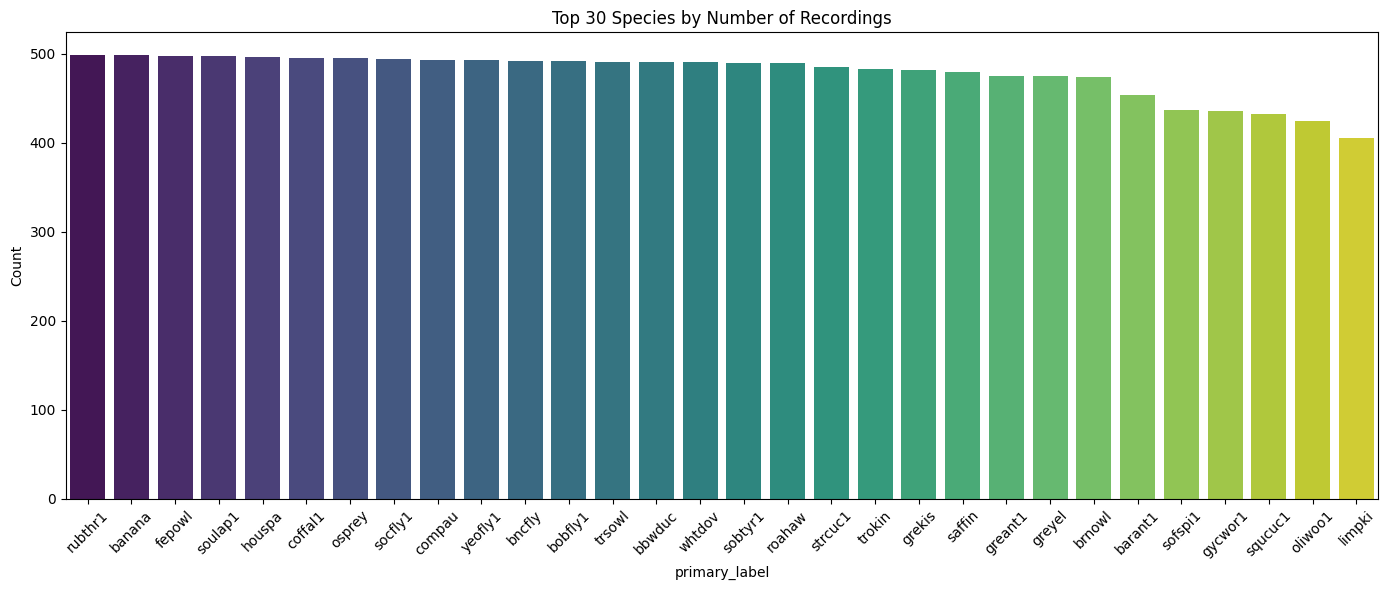

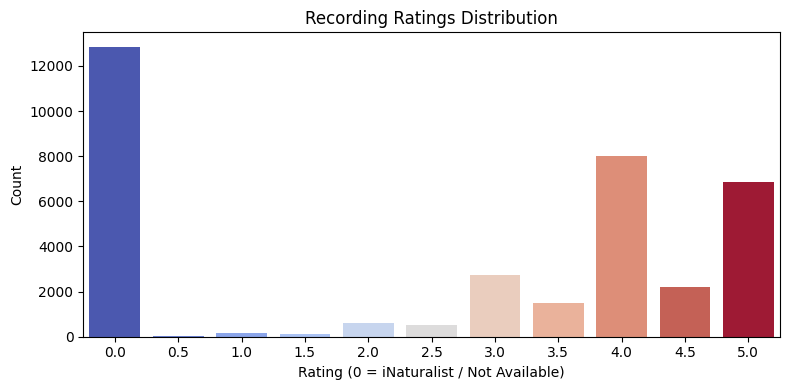

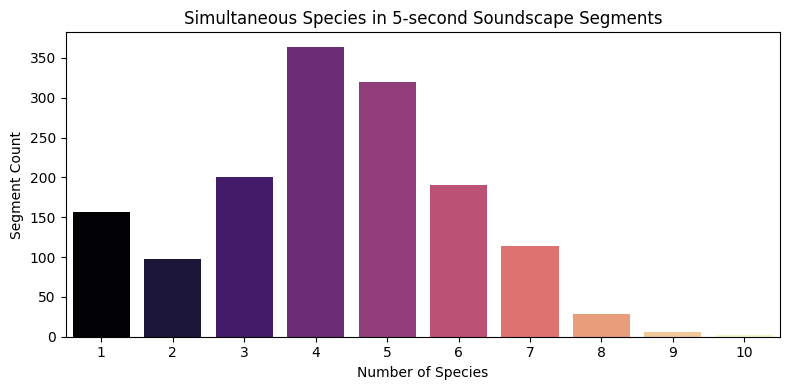

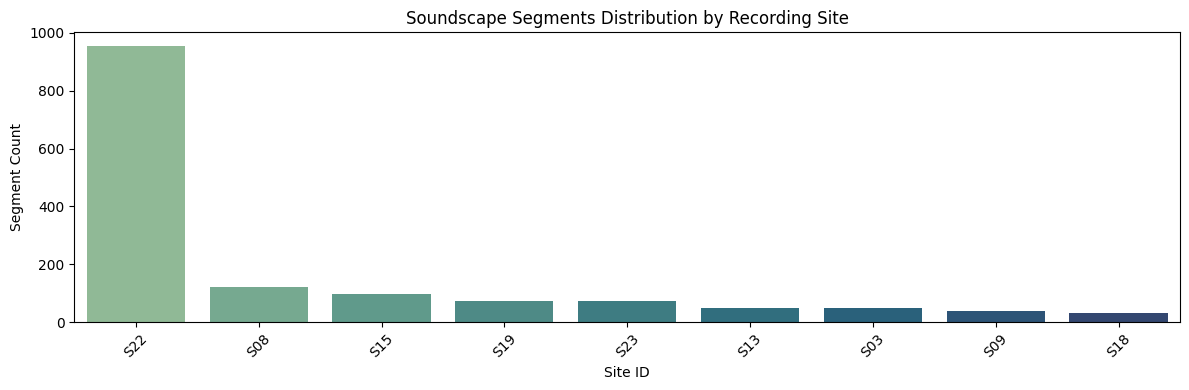

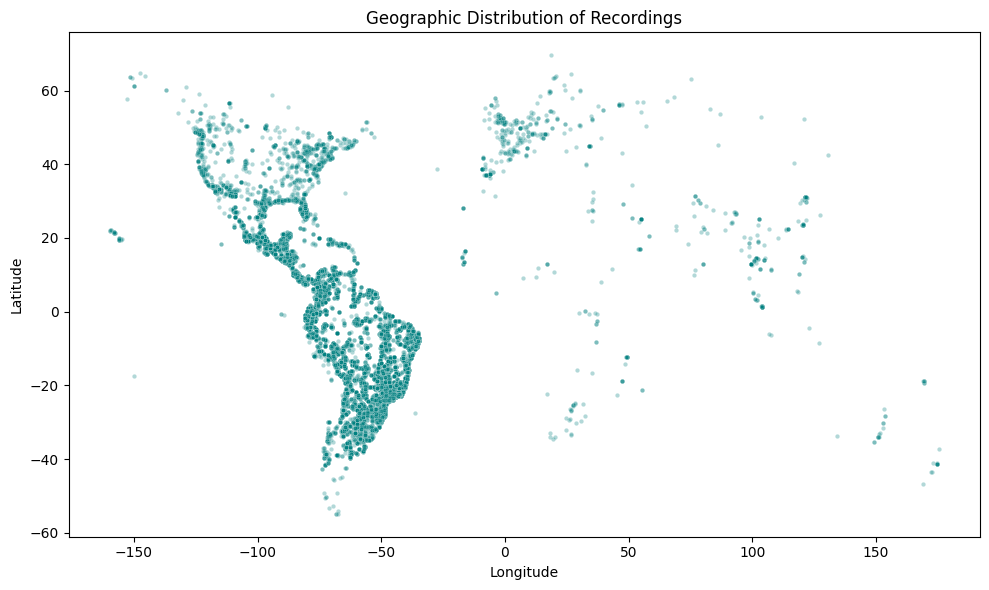

3 Random Focal Recordings (train_audio)
Species: spbant3 | File: spbant3/XC244114.ogg


Species: chbmoc1 | File: chbmoc1/XC387969.ogg


Species: lesela1 | File: lesela1/XC413849.ogg



1 Random Soundscape Recording (train_soundscapes)
Soundscape File: BC2026_Train_4960_S02_20240323_201500.ogg



Displaying High-Resolution PCEN Spectrograms (Max-RMS chunks for EDA only)

Primary Species: baffal1 | Secondary: [] | File: baffal1/XC8085.ogg


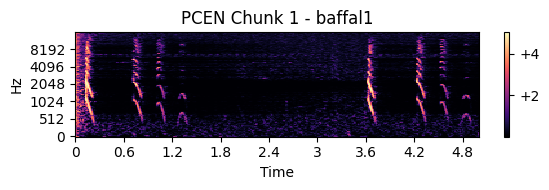

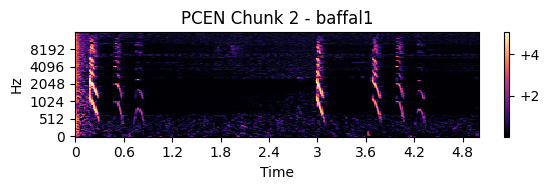

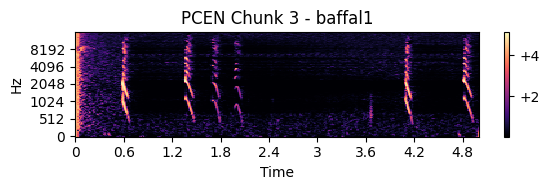


Primary Species: smbani | Secondary: [] | File: smbani/iNat838255.ogg


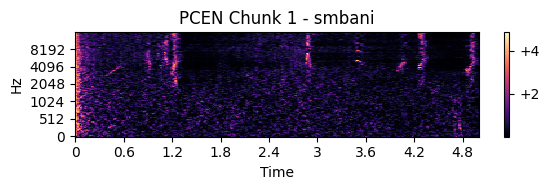

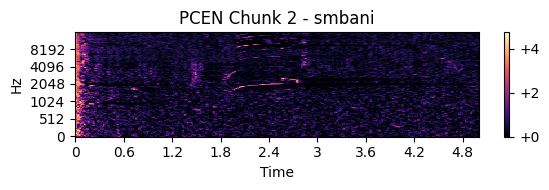

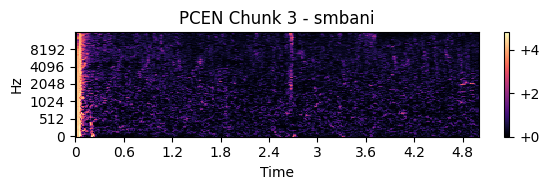

In [1]:
import os
import random
import ast
import re
import gc
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd
import librosa
import librosa.display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score
from scipy.ndimage import gaussian_filter1d
from tqdm.auto import tqdm

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
is_gpu = torch.cuda.is_available()
print(f"Using device: {device}")

base_path = '/kaggle/input/competitions/birdclef-2026'
train_csv_path = os.path.join(base_path, 'train.csv')
soundscapes_csv_path = os.path.join(base_path, 'train_soundscapes_labels.csv')
audio_dir = os.path.join(base_path, 'train_audio')
ss_audio_dir = os.path.join(base_path, 'train_soundscapes')
test_audio_dir = os.path.join(base_path, 'test_soundscapes')

train_df = pd.read_csv(train_csv_path)
soundscapes_df = pd.read_csv(soundscapes_csv_path)

# Top species distribution plot
plt.figure(figsize=(14, 6))
top_species = train_df['primary_label'].value_counts().head(30)
sns.barplot(x=top_species.index, y=top_species.values, hue=top_species.index, legend=False, palette='viridis')
plt.xticks(rotation=45)
plt.title('Top 30 Species by Number of Recordings')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

# Recording ratings distribution if available
if 'rating' in train_df.columns:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=train_df, x='rating', hue='rating', legend=False, palette='coolwarm')
    plt.title('Recording Ratings Distribution')
    plt.xlabel('Rating (0 = iNaturalist / Not Available)')
    plt.ylabel('Count')
    plt.tight_layout()
    plt.show()

# Simultaneous species per soundscape segment
soundscapes_df['label_count'] = soundscapes_df['primary_label'].apply(lambda x: len(str(x).split(';')))
label_dist = soundscapes_df['label_count'].value_counts().sort_index()

plt.figure(figsize=(8, 4))
sns.barplot(x=label_dist.index, y=label_dist.values, hue=label_dist.index, legend=False, palette='magma')
plt.title('Simultaneous Species in 5-second Soundscape Segments')
plt.xlabel('Number of Species')
plt.ylabel('Segment Count')
plt.tight_layout()
plt.show()

# Extract site ID from soundscape filenames (e.g., BC2026_Train_0039_S22_... -> S22)
soundscapes_df['site'] = soundscapes_df['filename'].apply(lambda x: x.split('_')[3])

# Soundscape segments distribution across recording sites EDA
plt.figure(figsize=(12, 4))
site_dist = soundscapes_df['site'].value_counts()
sns.barplot(x=site_dist.index, y=site_dist.values, hue=site_dist.index, legend=False, palette='crest')
plt.xticks(rotation=45)
plt.title('Soundscape Segments Distribution by Recording Site')
plt.xlabel('Site ID')
plt.ylabel('Segment Count')
plt.tight_layout()
plt.show()

# Geographic distribution of focal recordings
if 'latitude' in train_df.columns and 'longitude' in train_df.columns:
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=train_df, x='longitude', y='latitude', alpha=0.3, s=10, color='teal')
    plt.title('Geographic Distribution of Recordings')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.tight_layout()
    plt.show()

print("3 Random Focal Recordings (train_audio)")
focal_samples = train_df.sample(3)
for _, row in focal_samples.iterrows():
    audio_path = os.path.join(audio_dir, row['filename'])
    print(f"Species: {row['primary_label']} | File: {row['filename']}")
    if os.path.exists(audio_path):
        display(ipd.Audio(audio_path))
    else:
        print("File not found.")

print("\n1 Random Soundscape Recording (train_soundscapes)")
if os.path.exists(ss_audio_dir):
    soundscape_files = [f for f in os.listdir(ss_audio_dir) if f.endswith('.ogg')]
    if soundscape_files:
        random_soundscape = random.choice(soundscape_files)
        soundscape_path = os.path.join(ss_audio_dir, random_soundscape)
        print(f"Soundscape File: {random_soundscape}")
        display(ipd.Audio(soundscape_path))
    else:
        print("No soundscape audio files found in the directory.")
else:
    print("Soundscapes directory not found.")

def extract_top_chunks(audio_path, sr=32000, duration=5.0, n_mels=256, max_chunks=3):
    try:
        y, _ = librosa.load(audio_path, sr=sr)
    except Exception as e:
        print(f"Error loading {audio_path}: {e}")
        return [], []
        
    target_samples = int(sr * duration)
    total_samples = len(y)
    
    if total_samples <= target_samples:
        y_chunk = np.pad(y, (0, target_samples - total_samples))
        mel_spec = librosa.feature.melspectrogram(y=y_chunk, sr=sr, n_mels=n_mels, fmax=16000)
        pcen_spec = librosa.pcen(S=mel_spec * (2**31), sr=sr, hop_length=512, gain=0.98, bias=2, power=0.5, time_constant=0.4)
        return [y_chunk], [pcen_spec]
        
    num_full_chunks = total_samples // target_samples
    chunks = []
    energies = []
    
    for i in range(num_full_chunks):
        start = i * target_samples
        end = start + target_samples
        chunk = y[start:end]
        rms = np.mean(librosa.feature.rms(y=chunk))
        chunks.append(chunk)
        energies.append(rms)
        
    remainder = total_samples % target_samples
    if remainder > (target_samples // 2):
        chunk = np.pad(y[-remainder:], (0, target_samples - remainder))
        rms = np.mean(librosa.feature.rms(y=chunk))
        chunks.append(chunk)
        energies.append(rms)
        
    top_indices = np.argsort(energies)[-max_chunks:][::-1]
    best_y = []
    best_mels = []
    
    for idx in top_indices:
        best_y.append(chunks[idx])
        mel_spec = librosa.feature.melspectrogram(y=chunks[idx], sr=sr, n_mels=n_mels, fmax=16000)
        pcen_spec = librosa.pcen(S=mel_spec * (2**31), sr=sr, hop_length=512, gain=0.98, bias=2, power=0.5, time_constant=0.4)
        best_mels.append(pcen_spec)
        
    return best_y, best_mels

print("\nDisplaying High-Resolution PCEN Spectrograms (Max-RMS chunks for EDA only)")
sample_files = train_df.sample(2)
for _, row in sample_files.iterrows():
    audio_path = os.path.join(audio_dir, row['filename'])
    species = row['primary_label']
    secondary = row.get('secondary_labels', '[]')
    
    if os.path.exists(audio_path):
        print(f"\nPrimary Species: {species} | Secondary: {secondary} | File: {row['filename']}")
        y_chunks, pcen_specs = extract_top_chunks(audio_path, n_mels=256, max_chunks=3)
        
        for i, (y_chunk, pcen_spec) in enumerate(zip(y_chunks, pcen_specs)):
            plt.figure(figsize=(6, 2))
            librosa.display.specshow(pcen_spec, sr=32000, x_axis='time', y_axis='mel', fmax=16000)
            plt.colorbar(format='%+2.0f')
            plt.title(f'PCEN Chunk {i+1} - {species}')
            plt.tight_layout()
            plt.show()
            display(ipd.Audio(y_chunk, rate=32000))
    else:
        print(f"File {audio_path} not found.")

***DATASET GENERATION***

In [2]:
label_encoder = LabelEncoder()
train_df['label_encoded'] = label_encoder.fit_transform(train_df['primary_label'])
num_classes = len(label_encoder.classes_)

train_df['secondary_labels_list'] = train_df['secondary_labels'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) else []
)

def time_to_seconds(t_str):
    h, m, s = map(int, str(t_str).split(':'))
    return h * 3600 + m * 60 + s

def parse_labels(val):
    if pd.isna(val): return []
    return [str(l) for l in re.split(r'[;,\s]+', str(val).strip()) if l]

soundscapes_df['start_sec'] = soundscapes_df['start'].apply(time_to_seconds)
soundscapes_df['primary_label'] = soundscapes_df['primary_label'].apply(parse_labels)
# Extract site ID from filename for spatial cross-validation
soundscapes_df['site'] = soundscapes_df['filename'].apply(lambda x: x.split('_')[3])

class BirdWaveformDataset(Dataset):
    def __init__(self, df, audio_dir, label_encoder, target_sr=32000, duration=5.0, is_train=True):
        self.df = df
        self.audio_dir = audio_dir
        self.label_encoder = label_encoder
        self.num_classes = len(label_encoder.classes_)
        self.target_sr = target_sr
        self.target_samples = int(target_sr * duration)
        self.is_train = is_train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        file_path = os.path.join(self.audio_dir, row['filename'])
        
        try:
            waveform, sr = torchaudio.load(file_path)
        except Exception:
            waveform = torch.zeros(1, self.target_samples)
            sr = self.target_sr
            
        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0, keepdim=True)
            
        if sr != self.target_sr:
            resampler = T.Resample(sr, self.target_sr)
            waveform = resampler(waveform)
            
        if waveform.shape[1] > self.target_samples:
            if self.is_train:
                max_start = waveform.shape[1] - self.target_samples
                start = torch.randint(0, max_start, (1,)).item()
            else:
                start = 0
            waveform = waveform[:, start:start + self.target_samples]
        elif waveform.shape[1] < self.target_samples:
            pad_amount = self.target_samples - waveform.shape[1]
            waveform = torch.nn.functional.pad(waveform, (0, pad_amount))
            
        if self.is_train and torch.rand(1).item() < 0.5:
            noise_amplitude = 0.005 * torch.rand(1).item()
            waveform += torch.randn_like(waveform) * noise_amplitude
            
        target = torch.zeros(self.num_classes, dtype=torch.float32)
        target[row['label_encoded']] = 1.0
        
        for sec_species in row['secondary_labels_list']:
            if sec_species in self.label_encoder.classes_:
                sec_idx = self.label_encoder.transform([sec_species])[0]
                target[sec_idx] = 0.3
                
        return waveform, target

class SoundscapeWaveformDataset(Dataset):
    def __init__(self, df, audio_dir, label_encoder, target_sr=32000, duration=5.0):
        self.df = df
        self.audio_dir = audio_dir
        self.label_encoder = label_encoder
        self.num_classes = len(label_encoder.classes_)
        self.target_sr = target_sr
        self.frames_per_chunk = int(target_sr * duration)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        file_path = os.path.join(self.audio_dir, row['filename'])
        frame_offset = int(row['start_sec'] * self.target_sr)
        
        try:
            waveform, sr = torchaudio.load(file_path, frame_offset=frame_offset, num_frames=self.frames_per_chunk)
        except Exception:
            waveform = torch.zeros((1, self.frames_per_chunk))
            sr = self.target_sr
            
        if waveform.shape[0] > 1:
            waveform = torch.mean(waveform, dim=0, keepdim=True)
            
        if waveform.shape[1] < self.frames_per_chunk:
            waveform = torch.nn.functional.pad(waveform, (0, self.frames_per_chunk - waveform.shape[1]))
            
        target = torch.zeros(self.num_classes, dtype=torch.float32)
        for species in row['primary_label']:
            try:
                class_idx = self.label_encoder.transform([species])[0]
                target[class_idx] = 1.0
            except ValueError:
                pass
                
        return waveform, target

def get_dataloaders(use_group_split=False, batch_size=32):
    """
    Returns train, validation, and soundscape dataloaders.
    use_group_split=True: Purified split (Strictly isolates singletons, avoids spatial leakage).
    use_group_split=False: Naive random split (Duplicates singletons, causes spatial leakage).
    """
    df_balanced = train_df.groupby('primary_label').head(150).reset_index(drop=True)
    counts = df_balanced['primary_label'].value_counts()
    singletons = counts[counts == 1].index
    
    if use_group_split:
        df_singletons = df_balanced[df_balanced['primary_label'].isin(singletons)]
        df_multi = df_balanced[~df_balanced['primary_label'].isin(singletons)]
        
        train_multi, val_multi = train_test_split(
            df_multi, test_size=0.2, stratify=df_multi['label_encoded'], random_state=42
        )
        train_df_split = pd.concat([train_multi, df_singletons]).reset_index(drop=True)
        val_df_split = val_multi.reset_index(drop=True)
        print("Focal Data Split: GROUP SPLIT (Leakage Purified)")
        
        # Site-22 Split matching winning solution: Train on S22, Validate on other sites
        print("Soundscape Split: SITE-22 SPLIT (Train on S22, Val on other sites)")
        train_ss_df = soundscapes_df[soundscapes_df['site'] == 'S22'].reset_index(drop=True)
        val_ss_df = soundscapes_df[soundscapes_df['site'] != 'S22'].reset_index(drop=True)
    else:
        df_singletons = df_balanced[df_balanced['primary_label'].isin(singletons)]
        df_leaky = pd.concat([df_balanced, df_singletons], ignore_index=True)
        train_df_split, val_df_split = train_test_split(
            df_leaky, test_size=0.2, stratify=df_leaky['label_encoded'], random_state=42
        )
        print("Focal Data Split: RANDOM SPLIT (Leakage Present)")
        
        # Random Split for Soundscapes
        print("Soundscape Split: RANDOM SPLIT (Leakage Present)")
        train_ss_df, val_ss_df = train_test_split(
            soundscapes_df, test_size=0.2, random_state=42
        )

    train_dataset = BirdWaveformDataset(train_df_split, audio_dir, label_encoder, is_train=True)
    val_dataset = BirdWaveformDataset(val_df_split, audio_dir, label_encoder, is_train=False)
    
    train_loader = DataLoader(
        train_dataset, 
        batch_size=batch_size, 
        shuffle=True, 
        num_workers=4, 
        pin_memory=False,             
        persistent_workers=True,    
        drop_last=True
    )

    val_loader = DataLoader(
        val_dataset, 
        batch_size=batch_size, 
        shuffle=False, 
        num_workers=4, 
        pin_memory=False,
        persistent_workers=True
    )
    
    train_ss_dataset = SoundscapeWaveformDataset(train_ss_df, ss_audio_dir, label_encoder)
    val_ss_dataset = SoundscapeWaveformDataset(val_ss_df, ss_audio_dir, label_encoder)
    
    train_ss_loader = DataLoader(
        train_ss_dataset, 
        batch_size=batch_size, 
        shuffle=True, 
        num_workers=4, 
        pin_memory=False,
        persistent_workers=True,
        drop_last=True
    )

    val_ss_loader = DataLoader(
        val_ss_dataset, 
        batch_size=batch_size, 
        shuffle=False, 
        num_workers=4, 
        pin_memory=False,
        persistent_workers=True
    )
        
    return train_loader, val_loader, train_ss_loader, val_ss_loader

def apply_lss_injector(focal_waveforms, focal_labels, ss_waveforms, ss_labels, cap_value=0.5):
    """
    Winning Solution Technique: Mixes focal audio with real soundscapes.
    Caps soundscape labels to prevent overfitting on background noise.
    """
    capped_ss_labels = torch.clamp(ss_labels, max=cap_value)
    mixed_waveforms = (focal_waveforms + ss_waveforms) / 2.0
    mixed_labels = torch.max(focal_labels, capped_ss_labels)
    return mixed_waveforms, mixed_labels

***MODELS AND TRAINING LOOPS DEFINITION***

In [3]:
class AudioToSpectrogramGPU(nn.Module):
    def __init__(self, sr=32000, n_mels=256, n_fft=2048, hop_length=512, f_min=40, f_max=15000, use_pcen=True, use_specaugment=True):
        super().__init__()
        self.use_pcen = use_pcen
        self.use_specaugment = use_specaugment
        
        self.mel_spec = torchaudio.transforms.MelSpectrogram(
            sample_rate=sr, n_fft=n_fft, hop_length=hop_length,
            f_min=f_min, f_max=f_max, n_mels=n_mels, power=2.0 
        )
        
        self.eps = 1e-6
        self.s = 0.025
        self.alpha = 0.98
        self.delta = 2.0
        self.r = 0.5
        
        self.amp_to_db = torchaudio.transforms.AmplitudeToDB(stype='power', top_db=80)
        self.freq_mask = torchaudio.transforms.FrequencyMasking(freq_mask_param=36)
        self.time_mask = torchaudio.transforms.TimeMasking(time_mask_param=64)

    def forward(self, waveform):
        x = self.mel_spec(waveform)
        
        if self.use_pcen:
            ema = x.clone()
            for t in range(1, x.size(-1)):
                ema[..., t] = (1 - self.s) * ema[..., t - 1] + self.s * x[..., t]
            x = (x / (self.eps + ema)**self.alpha + self.delta)**self.r - self.delta**self.r
        else:
            x = self.amp_to_db(x)
            
        x = (x - x.mean()) / (x.std() + 1e-6)
        
        if self.training and self.use_specaugment:
            x = self.freq_mask(x)
            x = self.time_mask(x)
            
        return x

class SEBlock(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channels, channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channels // reduction, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y.expand_as(x)

class CNNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, pool_freq=2, pool_time=1, model_type='Asymmetric', use_se=True):
        super().__init__()
        self.use_se = use_se
        
        if model_type == 'Asymmetric':
            self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=(5, 1), padding=(2, 0), bias=False)
            self.bn1 = nn.BatchNorm2d(out_channels)
            self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=(1, 5), padding=(0, 2), bias=False)
            self.bn2 = nn.BatchNorm2d(out_channels)
        else:
            self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False)
            self.bn1 = nn.BatchNorm2d(out_channels)
            self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
            self.bn2 = nn.BatchNorm2d(out_channels)
            
        if self.use_se:
            self.se = SEBlock(out_channels)
            
        self.pool = nn.MaxPool2d(kernel_size=(pool_freq, pool_time))

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.relu(self.bn2(self.conv2(x)))
        if self.use_se:
            x = self.se(x)
        x = self.pool(x)
        return x

class ResNetBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, use_se=True):
        super().__init__()
        self.use_se = use_se
        
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        if self.use_se:
            self.se = SEBlock(out_channels)
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.use_se:
            out = self.se(out) 
        out += self.shortcut(x)
        return F.relu(out)

class AttentivePooling(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()
        self.attention = nn.Conv1d(in_channels, num_classes, kernel_size=1, bias=True)
        self.classifier = nn.Conv1d(in_channels, num_classes, kernel_size=1, bias=True)

    def forward(self, x):
        att_weights = torch.softmax(self.attention(x), dim=-1)
        frame_logits = self.classifier(x)
        clip_logits = torch.sum(att_weights * frame_logits, dim=-1)
        return clip_logits, frame_logits

class BirdSED_Model(nn.Module):
    def __init__(self, num_classes, model_type='Asymmetric', use_pcen=True, use_se=True, use_specaugment=True):
        super().__init__()
        self.model_type = model_type
        self.audio_extractor = AudioToSpectrogramGPU(use_pcen=use_pcen, use_specaugment=use_specaugment)
        
        if self.model_type in ['Asymmetric', 'Standard']:
            self.stem = nn.Sequential(
                nn.Conv2d(1, 32, kernel_size=5, stride=2, padding=2, bias=False),
                nn.BatchNorm2d(32),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
            )
            self.block1 = CNNBlock(32, 64, pool_freq=2, pool_time=1, model_type=model_type, use_se=use_se)
            self.block2 = CNNBlock(64, 128, pool_freq=2, pool_time=2, model_type=model_type, use_se=use_se)
            self.block3 = CNNBlock(128, 256, pool_freq=2, pool_time=2, model_type=model_type, use_se=use_se)
            self.block4 = CNNBlock(256, 512, pool_freq=2, pool_time=2, model_type=model_type, use_se=use_se)
            
        elif self.model_type == 'ResNet':
            self.conv1 = nn.Conv2d(1, 32, kernel_size=5, stride=2, padding=2, bias=False)
            self.bn1 = nn.BatchNorm2d(32)
            self.pool1 = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
            self.in_channels = 32
            self.layer1 = self._make_resnet_layer(64, stride=1, use_se=use_se)
            self.layer2 = self._make_resnet_layer(128, stride=2, use_se=use_se)
            self.layer3 = self._make_resnet_layer(256, stride=2, use_se=use_se)
            self.layer4 = self._make_resnet_layer(512, stride=2, use_se=use_se)
            
        self.freq_pool = nn.AdaptiveAvgPool2d((1, None))
        self.dropout = nn.Dropout(0.5)
        self.sed_head = AttentivePooling(in_channels=512, num_classes=num_classes)

    def _make_resnet_layer(self, out_channels, stride, use_se):
        layer = ResNetBlock(self.in_channels, out_channels, stride, use_se=use_se)
        self.in_channels = out_channels
        return layer

    def forward(self, waveform):
        x = self.audio_extractor(waveform)
        
        if self.model_type in ['Asymmetric', 'Standard']:
            x = self.stem(x)
            x = self.block4(self.block3(self.block2(self.block1(x))))
        elif self.model_type == 'ResNet':
            x = F.relu(self.bn1(self.conv1(x)))
            x = self.pool1(x)
            x = self.layer1(x)
            x = self.layer2(x)
            x = self.layer3(x)
            x = self.layer4(x)
            
        x = self.freq_pool(x).squeeze(2)
        x = self.dropout(x)
        clip_logits, _ = self.sed_head(x)
        return clip_logits

class FocalLoss(nn.Module):
    def __init__(self, alpha=1.0, gamma=2.0, reduction='mean'):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        bce_loss = F.binary_cross_entropy_with_logits(inputs, targets, reduction='none')
        pt = torch.exp(-bce_loss) 
        focal_loss = self.alpha * (1 - pt) ** self.gamma * bce_loss
        if self.reduction == 'mean':
            return focal_loss.mean()
        return focal_loss.sum()

def calculate_macro_roc_auc(all_true, all_probs):
    all_true = np.array(all_true)
    all_probs = np.array(all_probs)
    
    valid_classes = []
    for i in range(all_true.shape[1]):
        if len(np.unique(all_true[:, i])) > 1:
            valid_classes.append(i)
            
    if not valid_classes:
        return 0.0
        
    try:
        score = roc_auc_score(
            all_true[:, valid_classes], 
            all_probs[:, valid_classes], 
            average='macro'
        )
    except ValueError:
        score = 0.0
        
    return score

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def run_experiment(
    model_type='Asymmetric',
    use_pcen=True, 
    use_se=True, 
    use_specaugment=True,
    use_focal=True, 
    use_group_split=False, 
    use_mixup_lss=True,
    epochs_a=30, 
    epochs_b=15,
    batch_size=32,
    weights_dir='/kaggle/input/datasets/adrianosemerano/birdclef-phasea-weights'
):
    print(f"\nInitializing Experiment:")
    print(f"Model: {model_type} | PCEN: {use_pcen} | SE: {use_se} | SpecAugment: {use_specaugment}")
    print(f"Loss: {'Focal' if use_focal else 'BCE'} | Split: {'Group (No Leakage)' if use_group_split else 'Random (Leaky)'} | LSS Injector: {use_mixup_lss}")
    
    # Unified model naming for weights saving/loading
    features = []
    if use_pcen: features.append("PCEN")
    if use_se: features.append("SE")
    if use_mixup_lss: features.append("Mixup")
    if use_specaugment: features.append("Spec")
    if use_focal: features.append("Focal")
    
    suffix = "_".join(features) if features else ""
    prefix = "Leak_" if not use_group_split else ""
    model_name = f"{prefix}{model_type}_{suffix}" if suffix else f"{prefix}{model_type}"
    
    # Dual-path logic for Phase A weights
    model_filename_A = f'best_phaseA_{model_name}.pth'
    load_path_A = os.path.join(weights_dir, model_filename_A) # From Kaggle Dataset
    save_path_A = model_filename_A                            # Local Working Directory
    save_path_B = f'best_phaseB_{model_name}.pth'
    best_phase_a_path = None # Will store the actual path used
    
    train_loader, val_loader, train_ss_loader, val_ss_loader = get_dataloaders(use_group_split=use_group_split, batch_size=batch_size)
    
    model = BirdSED_Model(
        num_classes=num_classes, 
        model_type=model_type, 
        use_pcen=use_pcen, 
        use_se=use_se, 
        use_specaugment=use_specaugment
    ).to(device)
    
    print(f"Trainable Parameters: {count_parameters(model):,}")
    
    criterion = FocalLoss(alpha=1.0, gamma=2.0) if use_focal else nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    
    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=3e-3, steps_per_epoch=len(train_loader), 
        epochs=epochs_a, pct_start=0.2, div_factor=10.0
    )
    
    best_val_loss = float('inf')
    
    # Check dataset directory first, then local directory
    if os.path.exists(load_path_A):
        print(f"\nPhase A weights found in dataset ({load_path_A}). Skipping Phase A training.")
        model.load_state_dict(torch.load(load_path_A, map_location=device))
        best_phase_a_path = load_path_A
    elif os.path.exists(save_path_A):
        print(f"\nPhase A weights found locally ({save_path_A}). Skipping Phase A training.")
        model.load_state_dict(torch.load(save_path_A, map_location=device))
        best_phase_a_path = save_path_A
    else:
        print("\nStarting Phase A: Pre-training")
        best_phase_a_path = save_path_A
        
        for epoch in range(epochs_a):
            model.train()
            train_loss = 0.0
            train_bar = tqdm(train_loader, desc=f"Phase A [Epoch {epoch+1}/{epochs_a}]")
            
            ss_iter = iter(train_ss_loader) 
            
            for focal_waveforms, focal_labels in train_bar:
                focal_waveforms, focal_labels = focal_waveforms.to(device), focal_labels.to(device)
                
                if use_mixup_lss:
                    try:
                        ss_waveforms, ss_labels = next(ss_iter)
                    except StopIteration:
                        ss_iter = iter(train_ss_loader)
                        ss_waveforms, ss_labels = next(ss_iter)
                        
                    min_bs = min(focal_waveforms.size(0), ss_waveforms.size(0))
                    fw, fl = focal_waveforms[:min_bs], focal_labels[:min_bs]
                    sw, sl = ss_waveforms[:min_bs].to(device), ss_labels[:min_bs].to(device)
                    waveforms, labels = apply_lss_injector(fw, fl, sw, sl, cap_value=0.5)
                else:
                    waveforms = focal_waveforms
                    labels = focal_labels
                    
                optimizer.zero_grad()
                logits = model(waveforms)
                loss = criterion(logits, labels)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                scheduler.step()
                
                train_loss += loss.item()
                train_bar.set_postfix(Loss=f"{loss.item():.4f}", LR=f"{scheduler.get_last_lr()[0]:.5f}")
                
            model.eval()
            val_loss = 0.0
            all_probs = []
            all_true = []
            
            with torch.no_grad():
                for waveforms, labels in val_loader:
                    waveforms, labels = waveforms.to(device), labels.to(device)
                    logits = model(waveforms)
                    loss = criterion(logits, labels)
                    val_loss += loss.item()
                    
                    probs = torch.sigmoid(logits)
                    all_probs.append(probs.cpu().numpy())
                    all_true.append((labels > 0.5).int().cpu().numpy())
                    
            avg_val_loss = val_loss / len(val_loader)
            all_probs = np.vstack(all_probs)
            all_true = np.vstack(all_true)
            val_auc = calculate_macro_roc_auc(all_true, all_probs)
            
            print(f"Phase A Epoch [{epoch+1}/{epochs_a}] | Train Loss: {train_loss/len(train_loader):.4f} | Val Loss: {avg_val_loss:.4f} | Val ROC-AUC: {val_auc:.4f}")
            
            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
                torch.save(model.state_dict(), save_path_A)
                print(f"New best Phase A model saved locally! (Val Loss: {best_val_loss:.4f})")
            
    print("\nStarting Phase B: Fine-tuning")
    
    # Reload best Phase A weights (from dataset or local) before starting Phase B
    model.load_state_dict(torch.load(best_phase_a_path, map_location=device))
    optimizer_b = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    
    scheduler_b = optim.lr_scheduler.OneCycleLR(
        optimizer_b, max_lr=5e-4, steps_per_epoch=len(train_ss_loader), 
        epochs=epochs_b, pct_start=0.2, div_factor=10.0
    )
    
    best_val_loss_b = float('inf')
    
    for epoch in range(epochs_b):
        model.train()
        train_loss = 0.0
        train_bar = tqdm(train_ss_loader, desc=f"Phase B [Epoch {epoch+1}/{epochs_b}]")
        
        for waveforms, labels in train_bar:
            waveforms, labels = waveforms.to(device), labels.to(device)
            optimizer_b.zero_grad()
            logits = model(waveforms)
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer_b.step()
            scheduler_b.step()
            
            train_loss += loss.item()
            train_bar.set_postfix(Loss=f"{loss.item():.4f}")
            
        model.eval()
        val_loss = 0.0
        all_probs = []
        all_true = []
        
        with torch.no_grad():
            for waveforms, labels in val_ss_loader:
                waveforms, labels = waveforms.to(device), labels.to(device)
                logits = model(waveforms)
                loss = criterion(logits, labels)
                val_loss += loss.item()
                
                probs = torch.sigmoid(logits)
                all_probs.append(probs.cpu().numpy())
                all_true.append((labels > 0.5).int().cpu().numpy())
                
        avg_val_loss = val_loss / len(val_ss_loader)
        all_probs = np.vstack(all_probs)
        all_true = np.vstack(all_true)
        val_auc = calculate_macro_roc_auc(all_true, all_probs)
        
        print(f"Phase B Epoch [{epoch+1}/{epochs_b}] | Train Loss: {train_loss/len(train_ss_loader):.4f} | Val Loss: {avg_val_loss:.4f} | Val ROC-AUC: {val_auc:.4f}")
        
        if avg_val_loss < best_val_loss_b:
            best_val_loss_b = avg_val_loss
            torch.save(model.state_dict(), save_path_B)
            print(f"New best Phase B model saved! (Val Loss: {best_val_loss_b:.4f})")
            
    print(f"\nExperiment Finished. Best Phase B Val Loss: {best_val_loss_b:.4f}")
    
    model.load_state_dict(torch.load(save_path_B, map_location=device))
    return model

In [4]:
baseline_model = run_experiment(
    model_type='Asymmetric',
    use_pcen=True,
    use_se=False,
    use_specaugment=False,
    use_focal=False,
    use_group_split=True,
    use_mixup_lss=True,
    epochs_a=30 if is_gpu else 2,
    epochs_b=15 if is_gpu else 1,
    batch_size=32
)


Initializing Experiment:
Model: Asymmetric | PCEN: True | SE: False | SpecAugment: False
Loss: BCE | Split: Group (No Leakage) | LSS Injector: True
Focal Data Split: GROUP SPLIT (Leakage Purified)
Soundscape Split: SITE-22 SPLIT (Train on S22, Val on other sites)
Trainable Parameters: 2,827,260

Starting Phase A: Pre-training


Phase A [Epoch 1/30]:   0%|          | 0/516 [00:00<?, ?it/s]

Phase A Epoch [1/30] | Train Loss: 0.0617 | Val Loss: 0.0388 | Val ROC-AUC: 0.6185
New best Phase A model saved locally! (Val Loss: 0.0388)


Phase A [Epoch 2/30]:   0%|          | 0/516 [00:00<?, ?it/s]

Phase A Epoch [2/30] | Train Loss: 0.0478 | Val Loss: 0.0381 | Val ROC-AUC: 0.7330
New best Phase A model saved locally! (Val Loss: 0.0381)


Phase A [Epoch 3/30]:   0%|          | 0/516 [00:00<?, ?it/s]

... (81 outputs left out)

Phase B [Epoch 14/15]:   0%|          | 0/29 [00:00<?, ?it/s]

Phase B Epoch [14/15] | Train Loss: 0.0004 | Val Loss: 0.0746 | Val ROC-AUC: 0.8067


Phase B [Epoch 15/15]:   0%|          | 0/29 [00:00<?, ?it/s]

Phase B Epoch [15/15] | Train Loss: 0.0003 | Val Loss: 0.0749 | Val ROC-AUC: 0.8066

Experiment Finished. Best Phase B Val Loss: 0.0462
